# Step 5: Machine Learning Models - XGBoost & Neural Network
## AI-Assisted Health Risk Prediction for Life Insurance Underwriting

We train two modern ML models and compare them against the GLM baseline (Step 4):
1. **XGBoost** - gradient-boosted trees, captures non-linear interactions
2. **Neural Network (PyTorch)** = a feedforward MLP

Both use the **class-imbalance weight (`scale_pos_weight = 6.104`)** computed in
EDA, because unlike sklearn's logistic regression, they do NOT auto-compute it:
- XGBoost: `scale_pos_weight` parameter
- PyTorch: `pos_weight` in `BCEWithLogitsLoss`

Same test set + same metrics (AUROC, PR-AUC, F1) as Step 4 for a fair comparison.

## 5.1 Setup & Load Model-Ready Data

In [1]:
import pandas as pd
import numpy as np
import json
import joblib
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns

import xgboost as xgb
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             roc_curve, precision_recall_curve, confusion_matrix,
                             classification_report)
from sklearn.model_selection import train_test_split

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
print(f'xgboost {xgb.__version__}, torch {torch.__version__}')

xgboost 3.3.0, torch 2.13.0+cpu


In [2]:
# Robust path resolution (works from project root or Code/)
def find_dir(name):
    for base in [Path('.'), Path('..'), Path('..') / '..']:
        candidate = base / 'data' / name
        if candidate.exists():
            return candidate.resolve()
    raise FileNotFoundError(f'Could not locate data/{name}. Run notebook 03 first.')

MODEL_DIR = find_dir('model_ready')
RESULTS_DIR = MODEL_DIR.parent / 'results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = MODEL_DIR.parent / 'reports' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

X_train = pd.read_parquet(MODEL_DIR / 'X_train.parquet')
X_test = pd.read_parquet(MODEL_DIR / 'X_test.parquet')
y_train = pd.read_parquet(MODEL_DIR / 'y_train.parquet')['MORTSTAT']
y_test = pd.read_parquet(MODEL_DIR / 'y_test.parquet')['MORTSTAT']

with open(MODEL_DIR / 'preprocessing_metadata.json') as f:
    meta = json.load(f)
SCALE_POS_WEIGHT = meta['scale_pos_weight']

print(f'X_train: {X_train.shape}, X_test: {X_test.shape}')
print(f'scale_pos_weight: {SCALE_POS_WEIGHT}')

X_train: (14862, 84), X_test: (3716, 84)
scale_pos_weight: 6.104


In [3]:
# Helper to evaluate any model given predicted probabilities
def evaluate(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    return {
        'auroc': roc_auc_score(y_true, y_prob),
        'pr_auc': average_precision_score(y_true, y_prob),
        'f1': f1_score(y_true, y_pred),
        'y_pred': y_pred,
    }

## 5.2 Model A : XGBoost

Gradient-boosted decision trees. Trees split on value thresholds, so they can
capture **non-linear effects and interactions** (e.g., high HbA1c only matters
above a certain age) that the linear GLM cannot. We hold out a small validation
set for early stopping to avoid overfitting.

In [4]:
# Carve a validation set out of train for early stopping
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.15, stratify=y_train, random_state=RANDOM_STATE)

xgb_clf = xgb.XGBClassifier(
    n_estimators=600,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    reg_lambda=1.0,
    scale_pos_weight=SCALE_POS_WEIGHT,   # <-- handles class imbalance
    eval_metric='aucpr',
    early_stopping_rounds=40,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
xgb_clf.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
print(f'Best iteration: {xgb_clf.best_iteration}')

Best iteration: 347


In [5]:
# Evaluate XGBoost on the test set
xgb_prob = xgb_clf.predict_proba(X_test)[:, 1]
xgb_res = evaluate(y_test, xgb_prob)

print('=' * 45)
print('XGBoost — Test Metrics')
print('=' * 45)
print(f'AUROC  : {xgb_res["auroc"]:.4f}')
print(f'PR-AUC : {xgb_res["pr_auc"]:.4f}')
print(f'F1     : {xgb_res["f1"]:.4f}')
print()
print(classification_report(y_test, xgb_res['y_pred'], target_names=['Alive', 'Deceased']))

XGBoost — Test Metrics
AUROC  : 0.9070
PR-AUC : 0.6633
F1     : 0.6128

              precision    recall  f1-score   support

       Alive       0.96      0.88      0.92      3193
    Deceased       0.51      0.78      0.61       523

    accuracy                           0.86      3716
   macro avg       0.73      0.83      0.76      3716
weighted avg       0.90      0.86      0.87      3716



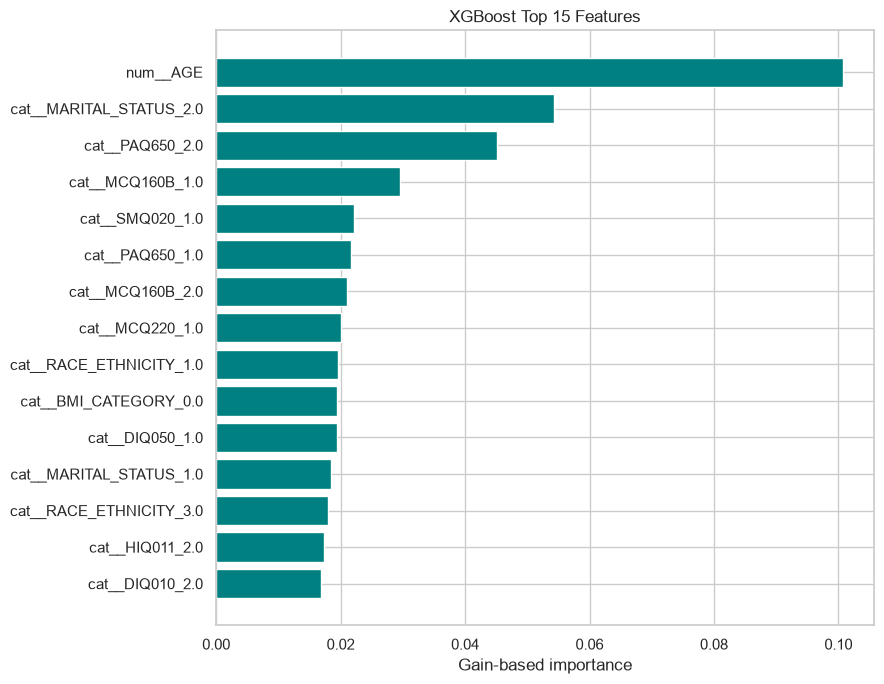

,feature,importance
0,num__AGE,0.100682
1,cat__MARITAL_STATUS_2.0,0.054315
2,cat__PAQ650_2.0,0.045071
3,cat__MCQ160B_1.0,0.029534
4,cat__SMQ020_1.0,0.022212
5,cat__PAQ650_1.0,0.021685
6,cat__MCQ160B_2.0,0.021083
7,cat__MCQ220_1.0,0.020063
8,cat__RACE_ETHNICITY_1.0,0.019557
9,cat__BMI_CATEGORY_0.0,0.019449


In [6]:
# XGBoost feature importance (top 15)
importance = pd.DataFrame({
    'feature': X_train.columns,
    'importance': xgb_clf.feature_importances_,
}).sort_values('importance', ascending=False)

top = importance.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top['feature'], top['importance'], color='teal')
ax.set_xlabel('Gain-based importance')
ax.set_title('XGBoost Top 15 Features')
plt.tight_layout()
plt.savefig(FIG_DIR / 'xgb_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
importance.head(15).reset_index(drop=True)

## 5.3 Model B - Neural Network (PyTorch MLP)

A feedforward multi-layer perceptron with dropout and batch norm for
regularization. Class imbalance is handled via `pos_weight` in
`BCEWithLogitsLoss` (the NN equivalent of `scale_pos_weight`).

In [7]:
# Convert data to tensors
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

X_tr_t = torch.tensor(X_tr.values, dtype=torch.float32)
y_tr_t = torch.tensor(y_tr.values, dtype=torch.float32).unsqueeze(1)
X_val_t = torch.tensor(X_val.values, dtype=torch.float32)
y_val_t = torch.tensor(y_val.values, dtype=torch.float32).unsqueeze(1)
X_test_t = torch.tensor(X_test.values, dtype=torch.float32).to(device)

train_loader = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=256, shuffle=True)
n_features = X_tr_t.shape[1]
print(f'Input features: {n_features}')

Using device: cpu
Input features: 84


In [8]:
class MLP(nn.Module):
    def __init__(self, n_in):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_in, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 1),   # logits (no sigmoid; BCEWithLogitsLoss applies it)
        )
    def forward(self, x):
        return self.net(x)

model = MLP(n_features).to(device)
print(model)

MLP(
  (net): Sequential(
    (0): Linear(in_features=84, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [9]:
# Loss with class-imbalance weight, optimizer
pos_weight = torch.tensor([SCALE_POS_WEIGHT], dtype=torch.float32).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)

# EARLY STOPPING CRITERION: validation PR-AUC.
# With ~14% positives, PR-AUC best reflects how well we detect the minority
# (deceased) class -- the hard, clinically important part of the task. We also
# log validation loss so both selection signals can be shown in the report.
EPOCHS = 60
EVAL_EVERY = 10          # evaluate on validation every N global steps
best_val_prauc = 0.0
best_step_seen = 0
best_state = None
patience, bad_evals = 20, 0   # patience counted in eval checkpoints

# Per-GLOBAL-STEP history (a step = one batch/optimizer update)
step_log = {'step': [], 'train_loss': []}
eval_log = {'step': [], 'val_loss': [],
            'val_auroc': [], 'train_auroc': [],
            'val_prauc': [], 'train_prauc': []}

X_val_dev = X_val_t.to(device)
y_val_dev = y_val_t.to(device)
X_tr_dev = X_tr_t.to(device)   # for computing training metrics at each eval

global_step = 0
stop = False
for epoch in range(EPOCHS):
    if stop:
        break
    for xb, yb in train_loader:
        model.train()
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()
        global_step += 1

        # Log training loss at every step
        step_log['step'].append(global_step)
        step_log['train_loss'].append(float(loss.item()))

        # Periodic validation evaluation (by global step)
        if global_step % EVAL_EVERY == 0:
            model.eval()
            with torch.no_grad():
                val_logits = model(X_val_dev)
                val_loss = criterion(val_logits, y_val_dev).item()
                val_prob = torch.sigmoid(val_logits).cpu().numpy().ravel()
                # Training AUROC on the same schedule (to compare train vs val)
                train_logits = model(X_tr_dev)
                train_prob = torch.sigmoid(train_logits).cpu().numpy().ravel()
            val_auroc = roc_auc_score(y_val.values, val_prob)
            train_auroc = roc_auc_score(y_tr.values, train_prob)
            val_prauc = average_precision_score(y_val.values, val_prob)
            train_prauc = average_precision_score(y_tr.values, train_prob)
            eval_log['step'].append(global_step)
            eval_log['val_loss'].append(float(val_loss))
            eval_log['val_auroc'].append(float(val_auroc))
            eval_log['train_auroc'].append(float(train_auroc))
            eval_log['val_prauc'].append(float(val_prauc))
            eval_log['train_prauc'].append(float(train_prauc))

            # Early stop on validation PR-AUC
            if val_prauc > best_val_prauc:
                best_val_prauc = val_prauc
                best_step_seen = global_step
                best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
                bad_evals = 0
            else:
                bad_evals += 1
                if bad_evals >= patience:
                    print(f'Early stopping at global step {global_step} (epoch {epoch+1})')
                    stop = True
                    break

    if (epoch + 1) % 10 == 0:
        print(f'Epoch {epoch+1:3d} | step {global_step} | val PR-AUC {eval_log["val_prauc"][-1]:.4f}')

# Restore best weights
model.load_state_dict(best_state)
print(f'\nTotal global steps: {global_step}')
print(f'Best validation PR-AUC: {best_val_prauc:.4f} (at step {best_step_seen})')

Early stopping at global step 320 (epoch 7)

Total global steps: 320
Best validation PR-AUC: 0.6504 (at step 120)


In [10]:
# Evaluate NN on the test set
model.eval()
with torch.no_grad():
    nn_prob = torch.sigmoid(model(X_test_t)).cpu().numpy().ravel()
nn_res = evaluate(y_test, nn_prob)

print('=' * 45)
print('Neural Network — Test Metrics')
print('=' * 45)
print(f'AUROC  : {nn_res["auroc"]:.4f}')
print(f'PR-AUC : {nn_res["pr_auc"]:.4f}')
print(f'F1     : {nn_res["f1"]:.4f}')
print()
print(classification_report(y_test, nn_res['y_pred'], target_names=['Alive', 'Deceased']))

Neural Network — Test Metrics
AUROC  : 0.9029
PR-AUC : 0.6525
F1     : 0.5599

              precision    recall  f1-score   support

       Alive       0.97      0.81      0.88      3193
    Deceased       0.42      0.85      0.56       523

    accuracy                           0.81      3716
   macro avg       0.69      0.83      0.72      3716
weighted avg       0.89      0.81      0.84      3716



### Neural Network Training Curves (by global step)

Training loss is logged at **every global step** (one optimizer update = one
mini-batch). Validation loss and AUROC are evaluated every 10 steps. These are
plotted against the global step (not epoch) for the report.

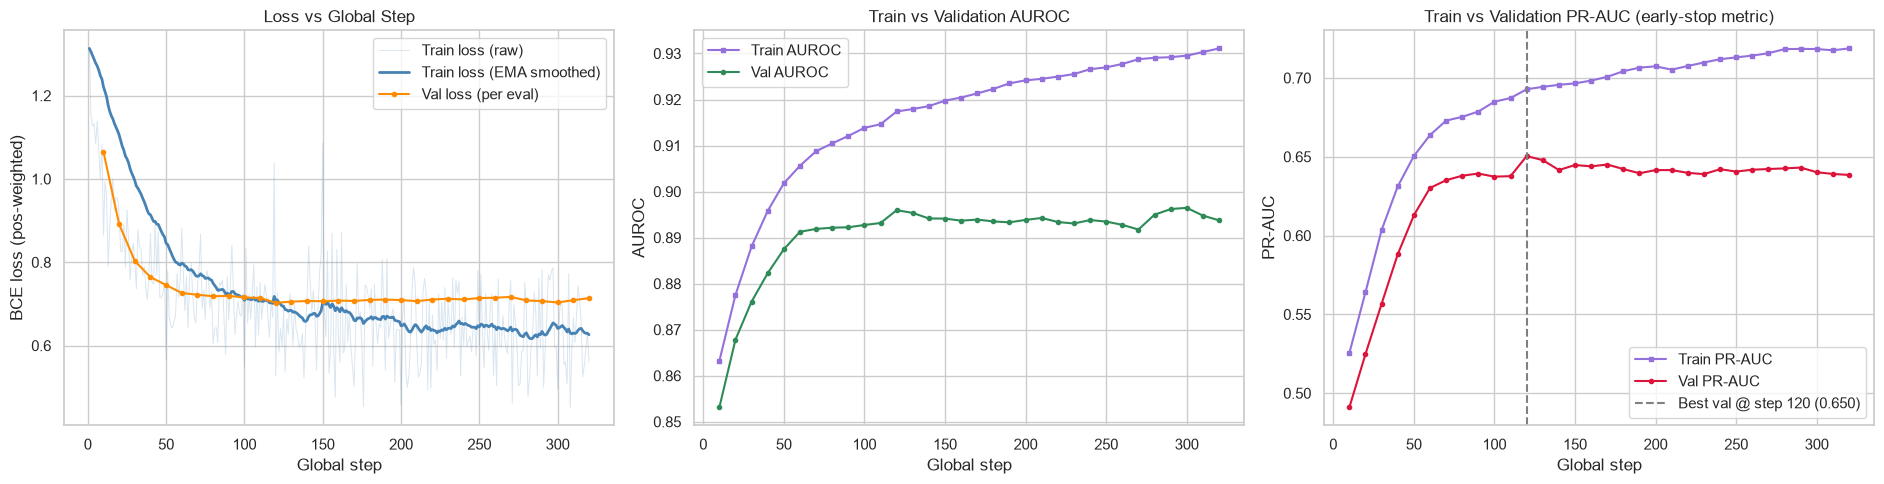

In [11]:
# Exponential moving average to smooth the jagged per-step training loss
def ema(values, alpha=0.05):
    out, s = [], values[0]
    for v in values:
        s = alpha * v + (1 - alpha) * s
        out.append(s)
    return out

train_loss_smooth = ema(step_log['train_loss'], alpha=0.05)

fig, ax = plt.subplots(1, 3, figsize=(19, 5))

# Panel 1: raw (faint) + EMA-smoothed training loss, plus validation loss
ax[0].plot(step_log['step'], step_log['train_loss'],
           color='steelblue', alpha=0.20, lw=0.7, label='Train loss (raw)')
ax[0].plot(step_log['step'], train_loss_smooth,
           color='steelblue', lw=2.0, label='Train loss (EMA smoothed)')
ax[0].plot(eval_log['step'], eval_log['val_loss'],
           color='darkorange', marker='o', ms=3, lw=1.5, label='Val loss (per eval)')
ax[0].set_xlabel('Global step')
ax[0].set_ylabel('BCE loss (pos-weighted)')
ax[0].set_title('Loss vs Global Step')
ax[0].legend()

# Panel 2: training vs validation AUROC
ax[1].plot(eval_log['step'], eval_log['train_auroc'],
           color='mediumpurple', marker='s', ms=3, lw=1.5, label='Train AUROC')
ax[1].plot(eval_log['step'], eval_log['val_auroc'],
           color='seagreen', marker='o', ms=3, lw=1.5, label='Val AUROC')
ax[1].set_xlabel('Global step')
ax[1].set_ylabel('AUROC')
ax[1].set_title('Train vs Validation AUROC')
ax[1].legend()

# Panel 3: training vs validation PR-AUC (the early-stopping criterion)
ax[2].plot(eval_log['step'], eval_log['train_prauc'],
           color='mediumpurple', marker='s', ms=3, lw=1.5, label='Train PR-AUC')
ax[2].plot(eval_log['step'], eval_log['val_prauc'],
           color='crimson', marker='o', ms=3, lw=1.5, label='Val PR-AUC')
ax[2].axvline(best_step_seen, ls='--', color='gray',
              label=f'Best val @ step {best_step_seen} ({best_val_prauc:.3f})')
ax[2].set_xlabel('Global step')
ax[2].set_ylabel('PR-AUC')
ax[2].set_title('Train vs Validation PR-AUC (early-stop metric)')
ax[2].legend()

plt.tight_layout()
plt.savefig(FIG_DIR / 'nn_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## 5.4 Model Comparison (GLM vs XGBoost vs Neural Network)

We load the GLM metrics saved in Step 4 and place all three side by side.

In [12]:
# Load shared metrics (contains GLM from Step 4), append ML models
metrics_path = RESULTS_DIR / 'model_metrics.json'
all_metrics = json.load(open(metrics_path)) if metrics_path.exists() else {}

all_metrics['XGBoost'] = {
    'auroc': round(float(xgb_res['auroc']), 4),
    'pr_auc': round(float(xgb_res['pr_auc']), 4),
    'f1': round(float(xgb_res['f1']), 4),
    'n_test': int(len(y_test)),
}
all_metrics['NeuralNetwork'] = {
    'auroc': round(float(nn_res['auroc']), 4),
    'pr_auc': round(float(nn_res['pr_auc']), 4),
    'f1': round(float(nn_res['f1']), 4),
    'n_test': int(len(y_test)),
}
with open(metrics_path, 'w') as f:
    json.dump(all_metrics, f, indent=2)

comparison = pd.DataFrame(all_metrics).T[['auroc', 'pr_auc', 'f1']]
comparison = comparison.sort_values('auroc', ascending=False)
print('Model comparison:')
comparison

Model comparison:


,auroc,pr_auc,f1
XGBoost,0.9070,0.6633,0.6128
GLM_LogisticRegression,0.9039,0.6490,0.5794
NeuralNetwork,0.9029,0.6525,0.5599


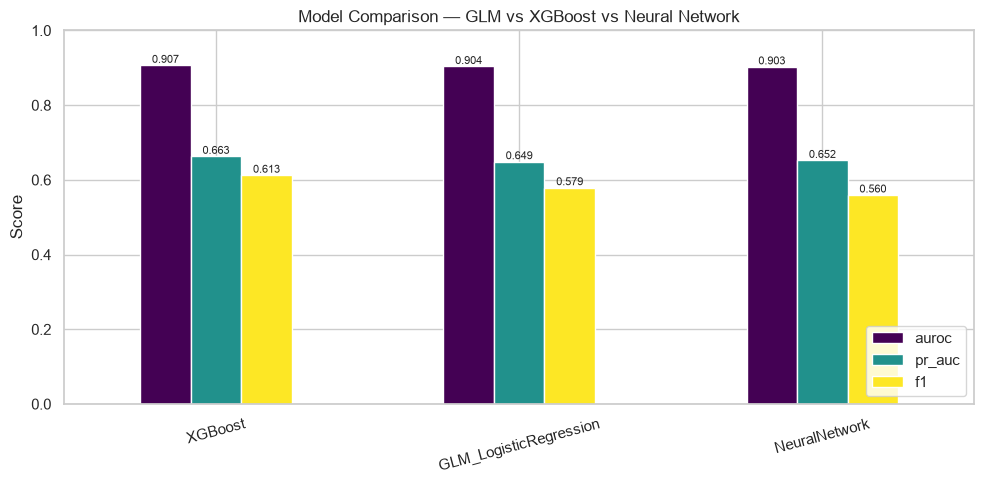

In [13]:
# Grouped bar chart of the comparison
ax = comparison.plot(kind='bar', figsize=(10, 5), colormap='viridis')
ax.set_ylabel('Score')
ax.set_title('Model Comparison — GLM vs XGBoost vs Neural Network')
ax.set_ylim(0, 1)
ax.legend(loc='lower right')
plt.xticks(rotation=15)
for c in ax.containers:
    ax.bar_label(c, fmt='%.3f', fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / 'model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

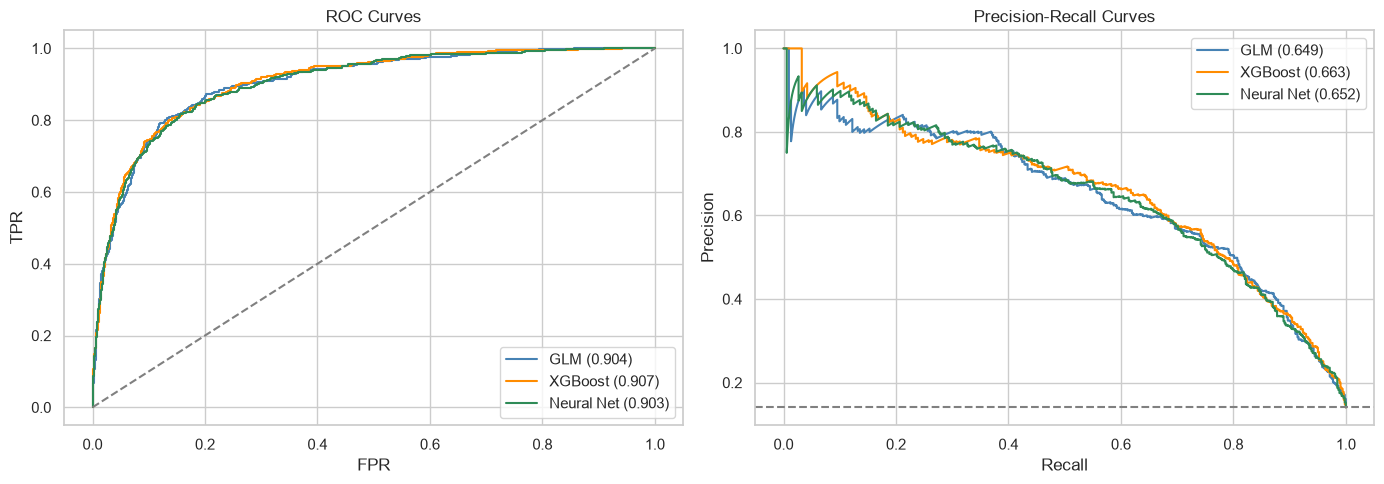

In [14]:
# Overlay ROC + PR curves for all three models
import joblib as _joblib
glm = _joblib.load(RESULTS_DIR / 'glm_model.joblib')
glm_prob = glm.predict_proba(X_test)[:, 1]

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for name, prob, color in [('GLM', glm_prob, 'steelblue'),
                          ('XGBoost', xgb_prob, 'darkorange'),
                          ('Neural Net', nn_prob, 'seagreen')]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax[0].plot(fpr, tpr, label=f'{name} ({roc_auc_score(y_test, prob):.3f})', color=color)
    prec, rec, _ = precision_recall_curve(y_test, prob)
    ax[1].plot(rec, prec, label=f'{name} ({average_precision_score(y_test, prob):.3f})', color=color)

ax[0].plot([0, 1], [0, 1], '--', color='gray')
ax[0].set_title('ROC Curves'); ax[0].set_xlabel('FPR'); ax[0].set_ylabel('TPR'); ax[0].legend()
ax[1].axhline(y_test.mean(), ls='--', color='gray')
ax[1].set_title('Precision-Recall Curves'); ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'all_models_roc_pr.png', dpi=150, bbox_inches='tight')
plt.show()

## 5.5 Save Trained Models

In [15]:
# Save XGBoost and the neural network for Step 6 (SHAP) and Step 7 (LLM)
joblib.dump(xgb_clf, RESULTS_DIR / 'xgboost_model.joblib')
torch.save(model.state_dict(), RESULTS_DIR / 'nn_model.pt')

# Save NN architecture info so it can be rebuilt for inference
nn_config = {'n_features': int(n_features), 'hidden': [128, 64], 'dropout': 0.3}
with open(RESULTS_DIR / 'nn_config.json', 'w') as f:
    json.dump(nn_config, f, indent=2)

print('Saved XGBoost + neural network models to', RESULTS_DIR)
for p in sorted(RESULTS_DIR.iterdir()):
    print(' -', p.name)

Saved XGBoost + neural network models to <PROJECT_ROOT>\data\results
 - final_results_summary.json
 - glm_coefficients.csv
 - glm_model.joblib
 - model_comparison_table.csv
 - model_metrics.json
 - nn_config.json
 - nn_model.pt
 - report_quality_check.csv
 - shap_explanations.json
 - shap_importance.csv
 - top_features_comparison.csv
 - underwriting_reports.json
 - xgboost_model.joblib


## Interpretation & Next Steps

**What to look for:**
- Do XGBoost / NN beat the GLM's AUROC (0.904) and PR-AUC (0.649)?
- Often on tabular clinical data the improvement is modest — a valid finding worth
  reporting (interpretable GLM is competitive with black-box models).
- XGBoost feature importance vs GLM coefficients: do they agree on top drivers?

**Proceed to Notebook 06: Explainability (SHAP)**
- Explain XGBoost (and optionally the NN) predictions with SHAP
- Produce per-patient explanations to feed the LLM underwriting report in Step 7